# 05 · Policy Explainability: How Does Each Agent Use the Battery?

From `code/explain.py`. Uses the hourly evaluation traces saved in notebook 03 to compare the battery action of each
PPO agent under different grid conditions.

- **Action** = building 0's battery charge rate: **positive = charging** (drawing from the grid),
  **negative = discharging** (covering load from the battery).
- **Grid states** are defined by percentiles of carbon intensity and electricity price over the year:
  "high" = ≥ 80th percentile, "low" = ≤ 20th percentile.

The interesting cells are the **conflict states**, where price and carbon point in opposite directions:
- *High carbon & low price* — cheap but dirty: a cost-only agent wants to charge, a carbon-aware one should not.
- *Low carbon & high price* — clean but expensive.

In [1]:
# Load all shared config, reward functions, environment wrapper and helpers from notebook 01
%run ./01_setup_and_core.ipynb

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Configuration loaded. Project root: D:\DEV\Projects\1_ResumeWorthy\SmartGridRL


In [2]:
EXPLAIN_SEED = 42
AGENTS = PPO_METHODS  # Cost-Only, Static, Static-Matched, Dynamic

traces = {}
for label in AGENTS:
    path = TABLES_DIR / f"{run_name(label, EXPLAIN_SEED)}_eval_trace.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run notebook 03 first")
    traces[label] = pd.read_csv(path)

# All agents see the same exogenous carbon / price series, so thresholds are taken from one trace
ref = traces['Dynamic']
carbon_p20, carbon_p80 = np.percentile(ref['carbon_intensity'], [20, 80])
price_p20, price_p80 = np.percentile(ref['pricing'], [20, 80])
print(f"Carbon intensity: p20 = {carbon_p20:.4f}, p80 = {carbon_p80:.4f}")
print(f"Electricity price: p20 = {price_p20:.4f}, p80 = {price_p80:.4f}")

Carbon intensity: p20 = 0.1263, p80 = 0.1854
Electricity price: p20 = 0.2100, p80 = 0.4000


## 1. Mean battery action per grid state
`hours` is how many of the 8,760 hours fall into each state. States with few hours give noisy averages —
read those rows with caution.

In [3]:
def grid_state_masks(df):
    hc = df['carbon_intensity'] >= carbon_p80
    lc = df['carbon_intensity'] <= carbon_p20
    hp = df['pricing'] >= price_p80
    lp = df['pricing'] <= price_p20
    return {
        'Overall': pd.Series(True, index=df.index),
        'High carbon': hc,
        'Low carbon': lc,
        'High price': hp,
        'Low price': lp,
        'High carbon & high price': hc & hp,
        'High carbon & low price': hc & lp,
        'Low carbon & high price': lc & hp,
        'Low carbon & low price': lc & lp,
    }

masks = grid_state_masks(ref)
action_table = pd.DataFrame({
    'hours': {state: int(mask.sum()) for state, mask in masks.items()},
    **{label: {state: df.loc[grid_state_masks(df)[state], 'action_b0'].mean() for state in masks}
       for label, df in traces.items()}
})
action_table.index.name = 'Grid state'
action_table.round(4)

,hours,Cost-Only,Static,Static-Matched,Dynamic
Grid state,,,,,
Overall,8759,-0.1389,-0.0656,-0.1512,-0.0829
High carbon,1752,-0.1501,-0.0261,-0.1350,-0.0420
Low carbon,1752,-0.1362,-0.1217,-0.1945,-0.1348
High price,1825,-0.3852,-0.2373,-0.3287,-0.2416
Low price,4617,-0.0854,-0.0228,-0.1080,-0.0585
High carbon & high price,669,-0.3609,-0.1961,-0.3150,-0.2099
High carbon & low price,289,-0.0348,0.0634,-0.0082,0.0141
Low carbon & high price,71,-0.3490,-0.1988,-0.3030,-0.2012
Low carbon & low price,1323,-0.1428,-0.1219,-0.1963,-0.1430


## 2. Visual comparison

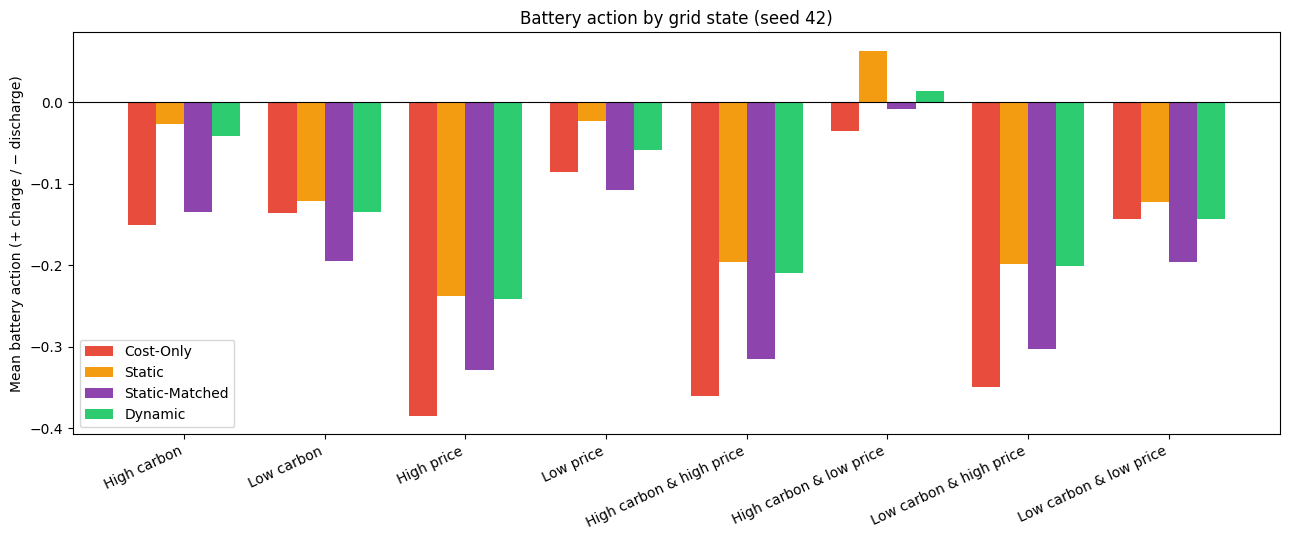

In [4]:
import matplotlib.pyplot as plt
# CityLearn switches matplotlib to the non-interactive Agg backend on import; switch back so plots show inline
%matplotlib inline

plot_states = [s for s in action_table.index if s != 'Overall']
x = np.arange(len(plot_states))
width = 0.8 / len(AGENTS)
fig, ax = plt.subplots(figsize=(13, 5.5))
for i, label in enumerate(AGENTS):
    ax.bar(x + (i - (len(AGENTS) - 1) / 2) * width, action_table.loc[plot_states, label], width, label=label, color=METHOD_COLORS[label])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(plot_states, rotation=25, ha='right')
ax.set_ylabel('Mean battery action (+ charge / − discharge)')
ax.set_title(f'Battery action by grid state (seed {EXPLAIN_SEED})')
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'explainability_actions_by_state.png', dpi=200)
plt.show()

## 3. Action vs carbon intensity, hour by hour
Mean action in each carbon-intensity decile. A carbon-aware policy should slope **downwards**:
less charging (more discharging) as the grid gets dirtier.

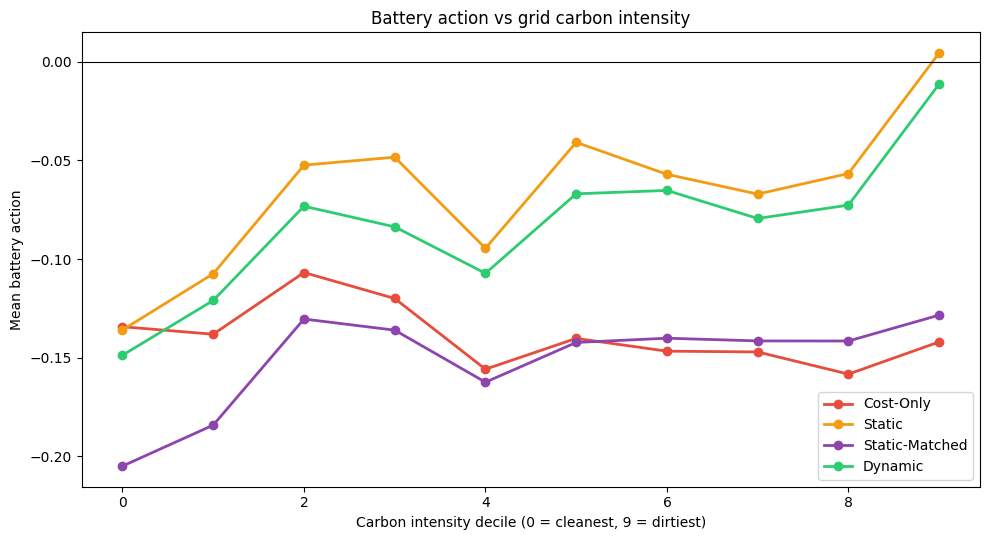

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
deciles = pd.qcut(ref['carbon_intensity'], 10, labels=False, duplicates='drop')
for label, df in traces.items():
    ax.plot(df.groupby(deciles)['action_b0'].mean(), marker='o', label=label, color=METHOD_COLORS[label], linewidth=2)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Carbon intensity decile (0 = cleanest, 9 = dirtiest)')
ax.set_ylabel('Mean battery action')
ax.set_title('Battery action vs grid carbon intensity')
ax.legend()
fig.tight_layout()
plt.show()

## 4. Written report
Saved to `01_notebook_pipeline/results/tables/explainability_report.md`. Headline numbers are read from the evaluation results
(notebook 04), not hard-coded.

In [6]:
raw = pd.read_csv(TABLES_DIR / 'evaluation_raw_results.csv')
means = raw.groupby('method')[['cost', 'carbon']].mean()
avoided = {m: means.loc['RBC', 'carbon'] - means.loc[m, 'carbon'] for m in AGENTS if m in means.index}
best = max(avoided, key=avoided.get)

conflict = 'High carbon & low price'
clean_exp = 'Low carbon & high price'
a = action_table

def agent_lines(state):
    return "\n".join(f"- {m}: `{a.loc[state, m]:.4f}`" for m in AGENTS)

report = f"""# Explainability Report: Policy Behavior Analysis

Battery actions of the PPO agents (building 0, evaluation seed {EXPLAIN_SEED}) under different grid conditions.
**Positive = charging**, **negative = discharging**. "High"/"low" = at or above the 80th / at or below the 20th percentile.

## 1. Mean action per grid state

{a.round(4).to_markdown()}

## 2. Conflict state: {conflict.lower()} ({a.loc[conflict, 'hours']} hours)
Electricity is cheap but the grid is dirty, so cost and carbon pull in opposite directions.

{agent_lines(conflict)}

Dynamic's mean action is {', '.join(f"{'lower' if a.loc[conflict, 'Dynamic'] < a.loc[conflict, m] else 'higher'} than {m}" for m in AGENTS if m != 'Dynamic')}
in this state (lower = less charging / more discharging).

## 3. Clean but expensive: {clean_exp.lower()} ({a.loc[clean_exp, 'hours']} hours)

{agent_lines(clean_exp)}

## 4. Emissions avoided vs RBC (mean over seeds)

""" + "\n".join(f"- {m}: {v:.2f} kg" for m, v in avoided.items()) + f"""

Largest carbon avoidance: **{best}** ({avoided[best]:.2f} kg).
"""

report_path = TABLES_DIR / 'explainability_report.md'
report_path.write_text(report, encoding='utf-8')
print(f"Explainability report written to {report_path}\n")
print(report)

Explainability report written to D:\DEV\Projects\1_ResumeWorthy\SmartGridRL\results\tables\explainability_report.md

# Explainability Report: Policy Behavior Analysis

Battery actions of the PPO agents (building 0, evaluation seed 42) under different grid conditions.
**Positive = charging**, **negative = discharging**. "High"/"low" = at or above the 80th / at or below the 20th percentile.

## 1. Mean action per grid state

| Grid state               |   hours |   Cost-Only |   Static |   Static-Matched |   Dynamic |
|:-------------------------|--------:|------------:|---------:|-----------------:|----------:|
| Overall                  |    8759 |     -0.1389 |  -0.0656 |          -0.1512 |   -0.0829 |
| High carbon              |    1752 |     -0.1501 |  -0.0261 |          -0.135  |   -0.042  |
| Low carbon               |    1752 |     -0.1362 |  -0.1217 |          -0.1945 |   -0.1348 |
| High price               |    1825 |     -0.3852 |  -0.2373 |          -0.3287 |   -0.2416 |
| L